In [2]:
pip install seaborn 


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns = iris.feature_names
)

df["species"] = iris.target_names[iris.target]

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  


In [8]:
print(df.shape)
print(df.info())
print(df.isnull().sum())
print(df["species"].value_counts())

(150, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


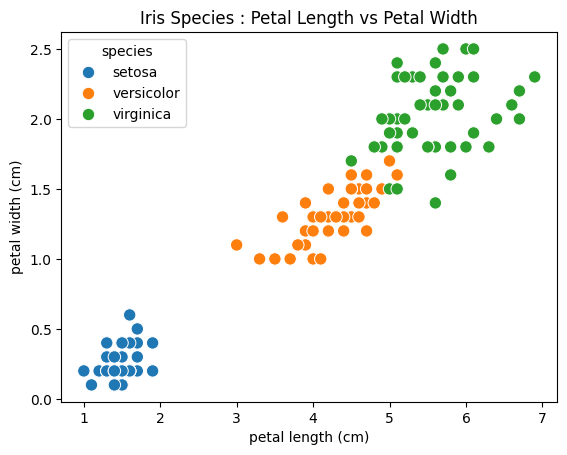

In [11]:
sns.scatterplot(
    data = df,
    x = "petal length (cm)",
    y = "petal width (cm)",
    hue = "species",
    s = 80
)

plt.title("Iris Species : Petal Length vs Petal Width")
plt.show()

In [12]:
x= df.drop(columns = "species")
y = df["species"]

print(x.head())
print(y.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


In [13]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

print("Training rows:", len(x_train))
print("Testing rows:", len(x_test))

Training rows: 120
Testing rows: 30


In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [20]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

model = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear")
)

model.fit(x_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(kernel='linear'))])

In [24]:
y_pred = model.predict(x_test)

print("predicted species:")
print(y_pred[:10])

print("\n Actual Species:")
print(y_test.iloc[:10].to_numpy())

predicted species:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']

 Actual Species:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']


In [25]:
results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted" : y_pred
})

results["correct"] = (
    results["Actual"] == results["Predicted"]
)

print(results.head(10))

       Actual   Predicted  correct
0      setosa      setosa     True
1   virginica   virginica     True
2  versicolor  versicolor     True
3  versicolor  versicolor     True
4      setosa      setosa     True
5  versicolor  versicolor     True
6      setosa      setosa     True
7      setosa      setosa     True
8   virginica   virginica     True
9  versicolor  versicolor     True


In [27]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("Accuracy percentage:", round(accuracy * 100,2), "%")

Accuracy: 1.0
Accuracy percentage: 100.0 %


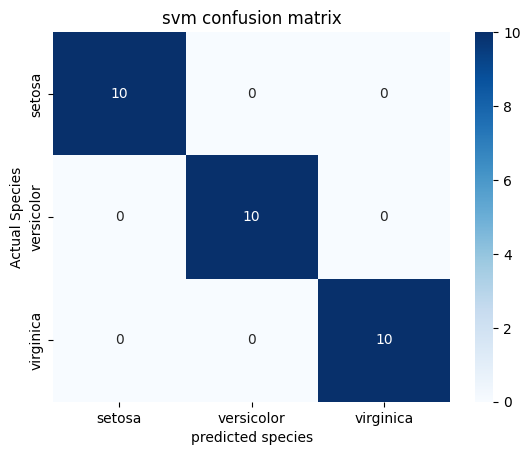

In [29]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels = iris.target_names
)

sns.heatmap(
    cm,
    annot = True,
    fmt = "d",
    cmap = "Blues",
    xticklabels = iris.target_names,
    yticklabels = iris.target_names
)

plt.xlabel("predicted species")
plt.ylabel("Actual Species")
plt.title("svm confusion matrix")
plt.show()

In [30]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [31]:
from sklearn.metrics import accuracy_score

for kernel in ["linear","rbf","poly"]:
    model = make_pipeline(
        StandardScaler(),
        SVC(kernel = kernel)
    )

    model.fit(x_train,y_train)
    predictions = model.predict(x_test)

    print(
        kernel,
        round(accuracy_score(y_test, predictions), 4)
    )
    
    

linear 1.0
rbf 0.9667
poly 0.9


In [38]:
from sklearn.model_selection import GridSearchCV

pipeline = make_pipeline(
    StandardScaler(),
    SVC()
)

param_grid = {
    "svc__kernel": ["linear", "rbf"],
    "svc__C": [0.1,1,10,100],
    "svc__gamma": ["scale", 0.1, 1]
}

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv =5,
    scoring = "accuracy"
)

grid.fit(x_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 4))

Best parameters: {'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
Best CV accuracy: 0.975


In [39]:
best_model = grid.best_estimator_

final_predictions = best_model.predict(x_test)

print(
    "Final test accuracy:",
    round(accuracy_score(y_test, final_predictions), 4)
)

Final test accuracy: 0.9333


In [40]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns = iris.feature_names
)

prediction = best_model.predict(new_flower)

print("predicted species:", prediction[0])

predicted species: setosa
